# Interfacing Keldysh model with TTM

Documentation of the library is given here: 
http://cybertib.celeonet.fr/spp-extended-theory/namespacelibKeldysh.html

and details as
gammaKeldysh (Egap, meff, Efield, wavelength, RefractiveIndex=1.)

In [1]:
from spp_extended_theory.Keldysh.libKeldysh import gammaKeldysh, Keldysh1phi, Keldysh2theta, EffectiveGap, KeldyshFunction_Gruzdev, IonizationRate_Gruzdev
# from spp_extended_theory.Keldysh    import Keldysh
from scipy.constants import e, h, hbar, c, epsilon_0
import numpy as np

  spp_extended_theory.Keldysh.libKeldyshZhukov - <module> - DEBUG - Path prefix=/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/Keldysh/


In [2]:
Egap=9*e
wavelength=2.08e-6 #m
NumberOfPhotons=np.ceil((h*c/wavelength)**-1 * Egap)
print("Number of MPI photons: ", NumberOfPhotons)
meff=1e0
Efield=np.linspace(1,1E10,10)
intensity=0.5*c*epsilon_0*Efield**2
print(intensity)
print(np.shape(Efield))
gammaKeldysh(Egap, meff, Efield, wavelength)

Number of MPI photons:  16.0
[1.32720936e-03 1.63853008e+15 6.55412032e+15 1.47467707e+16
 2.62164813e+16 4.09632520e+16 5.89870829e+16 8.02879739e+16
 1.04865925e+17 1.32720936e+17]
(10,)


array([6.47810215e+09, 5.83029193e+00, 2.91514597e+00, 1.94343064e+00,
       1.45757298e+00, 1.16605839e+00, 9.71715323e-01, 8.32898848e-01,
       7.28786492e-01, 6.47810215e-01])

## Ideas 

A great page that makes a nice summary of the possibilities https://scipy-lectures.org/advanced/interfacing_with_c/interfacing_with_c.html

### 1. Simplest interface
1. Generate the file containing wPI[internal intensities]
1. Write it into a file
1. Load the file in memory with Flirt C code. 
1. Interpolate linearly between the intensities to compute the right value for execution (RAM based only). 

### 2. A bit more integration
1. To prepare the contents in memory using libKeldysh. 
1. To transfer the memory content directly to C (using Numpy C API: https://numpy.org/doc/stable/reference/c-api/coremath.html#numpy-core-math-library). Think that elliptical functions are necessary for Keldysh routines. 

### 3. Wrapping Flirt code into Cython.
1. ?

## Implementation

### Simplest interface

This first part is doing something equivalent to keldysh.py, better summarized. 

In [3]:
from octopus_slabs.Libs.libMaterials import SiBulkReal300K
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, epsilon_0

Egap, meff, OpticalIndex = SiBulkReal300K()
print(Egap/e)

3.0999999999999996


### Should we get wavelength in input file? 

In [4]:
wavelength = 800E-9

# Here we shall define min and max of intensity necessary for 1 run.

LogPeakIntensity=np.arange(0,18,1E-3)
PeakIntensity = np.power(10.,LogPeakIntensity) #Zhukov example at 1.6 um
RefractiveIndex = OpticalIndex[wavelength] #1: for far field, # 1.45: for near field in silica
PeakField   = np.sqrt(2e0 * PeakIntensity * RefractiveIndex / (c * epsilon_0))
order=200

In [5]:
gamma   = gammaKeldysh(Egap, meff, PeakField, wavelength)
k1      = Keldysh1phi(gamma); k2 = Keldysh2theta(gamma)
EgapEff = EffectiveGap(Egap, k1, k2)
KeldyshFunctionResultG = KeldyshFunction_Gruzdev( k1, k2, EgapEff, order, wavelength )
wPIg    = IonizationRate_Gruzdev(k1, k2, KeldyshFunctionResultG, EgapEff, wavelength, meff)

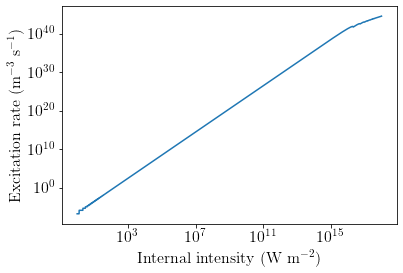

In [6]:
plt.loglog(PeakIntensity, wPIg, "-")
plt.xlabel(r"Internal intensity (W m$^{-2}$)")
plt.ylabel(r"Excitation rate (m$^{-3}$ s$^{-1}$)")
plt.show()

We are now able to grab a Keldysh excitation rate $w_{PI}$ directly from a set of parameters. 

In [7]:
import spp_extended_theory.Libs.libDatabase as libDatabase
ArrayToExport=np.array([PeakIntensity, np.log10(wPIg)]).T
libDatabase.ExportToTxt(ArrayToExport, "Keldysh.dat", header="Gap: "+str(round(Egap/e,1))+"eV\nWavelength: "+str(1E9*wavelength)+"nm"+"\nn x I\tWpiKG")

0

The second part is now preparing a database of Keldysh excitation rates for a number of fields. This is equivalent to the function libKeldysh.generateWpiTables(). 

In [8]:
!pwd

/home/thibault.derrien/Documents/octopus-slabs/Maths/Tibo-biatrisrv


# Interfacing TDDFT database with TTM

## Opening database

In [2]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


In [3]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [16]:
data=pd.read_csv("SiComplete-2021-12-19-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


In [18]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid==24]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.000000,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.50,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.000000,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.50,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.000000,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.00,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.000000,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.50,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.000000,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.00,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2477,460337.0,20210607.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.628319,2.656000e-06,...,0.000000,0.317643,-6.721950e+14,2.499799e+27,1.794610e+41,1.792613e+41,1.0,0.0,3266.25,1153.010893
2478,460330.0,20210606.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,-0.471239,2.656000e-06,...,0.000000,0.316438,-6.758071e+14,2.507067e+27,1.794057e+41,1.797825e+41,1.0,0.0,3266.25,1153.010893
2479,460361.0,20210613.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.785398,1.099557,2.656000e-06,...,0.000000,39.889875,-2.040417e+15,8.658356e+28,6.209462e+42,6.208932e+42,1.0,0.0,3266.25,1153.010893
2480,460345.0,20210609.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.785398,-1.413717,2.656000e-06,...,0.000000,39.842430,3.083916e+15,8.676632e+28,6.221966e+42,6.222038e+42,1.0,0.0,3266.25,1153.010893


In [20]:
data=data[data.CEP1==0]; 
data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.0,0.0,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.50,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.50,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.00,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.50,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.00,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2423,509502.0,20210821.0,24.0,0.434637,1.367968e-06,4.563000e-15,5.000000e+09,0.0,0.0,6.839800e-07,...,0.000000,10.230212,-1.782983e+15,4.011485e+28,8.790671e+42,8.791333e+42,3.0,2.0,1508.75,377.283440
2424,511497.0,20210827.0,24.0,0.434637,1.367968e-06,4.563000e-15,1.000000e+09,0.0,0.0,6.839800e-07,...,0.000000,0.021075,-3.711196e+14,4.041034e+26,8.855961e+40,8.856091e+40,3.0,2.0,1508.75,377.283440
2425,509443.0,20210821.0,24.0,0.434637,1.367968e-06,4.563000e-15,1.000000e+09,0.0,0.0,6.839800e-07,...,0.000000,0.020816,-2.967067e+14,3.699967e+26,8.108645e+40,8.108628e+40,3.0,2.0,1508.75,377.283440
2426,509501.0,20210821.0,24.0,0.434637,1.367968e-06,4.563000e-15,4.000000e+09,0.0,0.0,6.839800e-07,...,0.000000,4.704427,-1.160023e+15,2.559743e+28,5.609811e+42,5.609780e+42,3.0,2.0,1508.75,377.283440


In [21]:
wavelength=800e-9
data=data[data.lambda1==wavelength]
data=data[data.tau1==30e-15]
data=data[data.Efield2==0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
6,5026870.0,20180521.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.0,0.0,8.000000e-07,...,0.006720,0.031501,-4.435532e+13,2.365529e+26,7.879395e+39,7.885098e+39,3.0,2.0,3475.0,1350.561171
26,5027570.0,20180523.0,24.0,0.434637,8.000000e-07,3.000000e-14,5.500000e+08,0.0,0.0,8.000000e-07,...,0.002746,0.012099,-7.593778e+12,9.223486e+25,3.069200e+39,3.074495e+39,3.0,2.0,3250.0,1350.561171
56,4987848.0,20180519.0,24.0,0.434637,8.000000e-07,3.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,2.164194,103.432533,8.172043e+15,8.895337e+28,2.965071e+42,2.965112e+42,3.0,2.0,2350.0,1350.561171
77,5027579.0,20180523.0,24.0,0.434637,8.000000e-07,3.000000e-14,5.500000e+09,0.0,0.0,8.000000e-07,...,0.636744,12.201031,-1.183287e+15,2.849495e+28,9.495732e+41,9.498316e+41,3.0,2.0,2512.5,1350.561171
128,5027576.0,20180523.0,24.0,0.434637,8.000000e-07,3.000000e-14,2.500000e+09,0.0,0.0,8.000000e-07,...,0.146616,1.160959,-6.864432e+14,5.757010e+27,1.919140e+41,1.919003e+41,3.0,2.0,2875.0,1350.561171
149,5027582.0,20180524.0,24.0,0.434637,8.000000e-07,3.000000e-14,8.500000e+09,0.0,0.0,8.000000e-07,...,1.596982,56.248719,8.165564e+15,6.700422e+28,2.233887e+42,2.233474e+42,3.0,2.0,2212.5,1350.561171
235,5027581.0,20180524.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.500000e+09,0.0,0.0,8.000000e-07,...,1.307995,37.251917,9.390003e+13,5.507477e+28,1.836770e+42,1.835826e+42,3.0,2.0,2287.5,1350.561171
242,5026865.0,20180521.0,24.0,0.434637,8.000000e-07,3.000000e-14,2.000000e+08,0.0,0.0,8.000000e-07,...,0.000082,0.000225,-1.185274e+12,1.584157e+24,5.114378e+37,5.280523e+37,3.0,2.0,3712.5,1350.561171
273,5027566.0,20180523.0,24.0,0.434637,8.000000e-07,3.000000e-14,1.500000e+08,0.0,0.0,8.000000e-07,...,0.000036,0.000083,1.515717e+12,5.025577e+23,1.585037e+37,1.675192e+37,3.0,2.0,3562.5,1350.561171
285,5026874.0,20180521.0,24.0,0.434637,8.000000e-07,3.000000e-14,3.000000e+09,0.0,0.0,8.000000e-07,...,0.181275,1.760588,-4.441854e+14,7.399583e+27,2.466914e+41,2.466528e+41,3.0,2.0,3012.5,1350.561171


## Sorting out

In [22]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

## Plotting

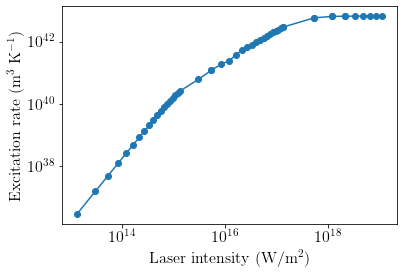

In [23]:
from scipy.constants import c, epsilon_0, e
PeakIntensity = 0.5*c*epsilon_0*data.Efield1**2
Wpi = data.Wpi
plt.loglog(PeakIntensity, Wpi, "-o")
plt.xlabel(r"Laser intensity (W/m$^{2}$)")
plt.ylabel(r"Excitation rate (m$^{3}$ K$^{-1}$)")
plt.show()

## How to treat low fields, then? 

It appears we may have to use Nikita's model? 
At low intensity, we don't have access to the quantity. 
Or to use some extrapolation methods out of the boundaries? Something like machine learning? 
We can actually re-use routines I had prepared in octopus-slabs/MachineLearning !

### Application of linear regression

In [17]:
from sklearn import linear_model
dataset_in = np.log10(np.array([data.lambda1, data.tau1, data.Efield1]).T)
dataset_out = np.log10(data.Wpi)
print("=== Shapes ===")
print((np.shape(dataset_in)))
print((np.shape(dataset_out)))
print("==== Learning ===")
alpha_val = 1E0
reg = linear_model.Lasso(alpha=alpha_val, max_iter=10000000, random_state=True, positive=True, normalize=False, copy_X=False, fit_intercept = False, precompute=False)
# reg = linear_model.Ridge(alpha=alpha_val, copy_X=False, fit_intercept=True, max_iter=None, normalize=True, random_state=True)
reg.fit(dataset_in,dataset_out)


=== Shapes ===
(50, 3)
(50,)
==== Learning ===


Lasso(copy_X=False, fit_intercept=False, max_iter=10000000, positive=True,
      random_state=True)

=== Prediction ===


  matplotlib.font_manager - _findfont_cached - WARNING - findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.


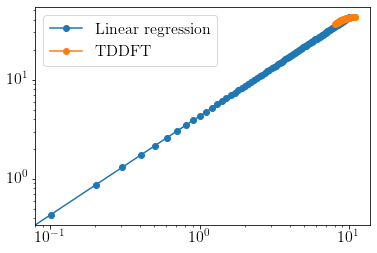

In [18]:
print("=== Prediction ===")
lambda1=800e-9
tau1=10e-15
Efield1_log = np.linspace(0, 10, 100)
Efield1_t=np.log10([1E6, 1E7, 1E8, 1E9])
extrapolated=[]
for Efield1 in Efield1_log:
    #print(np.shape(dataset_in))
    result=reg.predict([[lambda1, tau1, Efield1]])
    extrapolated.append(result)

extrapolated_t=(np.array(extrapolated))

plt.loglog(Efield1_log, extrapolated_t, "-o", label="Linear regression")
plt.loglog(np.log10(data.Efield1), np.log10(data.Wpi), "-o", label="TDDFT")
plt.legend(loc="best")

Linear regression fails epically. 

### Piecewise interpolation

In [129]:
from scipy.constants import c, epsilon_0, e
import pwlf
model = pwlf.PiecewiseLinFit(np.log10(0.5*c*epsilon_0*data.Efield1**2), np.log10(data.Wpi))
# Efield1_log = np.linspace(np.min(np.log10(data.Efield1)), np.max(np.log10(data.Efield1)), 100) #good for checking
# Efield1_log = np.linspace(-15, np.max(np.log10(data.Efield1)), 500_000) #good for export
Intensity_log = np.linspace(-15, np.max(np.log10(0.5*c*epsilon_0*data.Efield1**2)), 500_000) #good for export
print(Intensity_log)
I_th=model.fit(3)
print("Threshold intensities: "+str(I_th))
n_ph=model.slopes
print("Number of photons: "+str(n_ph))

[-15.         -14.99993194 -14.99986387 ...  19.03128833  19.03135639
  19.03142446]
Threshold intensities: [13.12293944 15.0535809  17.3837266  19.03142446]
Number of photons: [2.00292486 1.03037248 0.03750879]


In [130]:
model.predict(Intensity_log)

array([-19.82288067, -19.82274435, -19.82260802, ...,  42.83489983,
        42.83490238,  42.83490493])

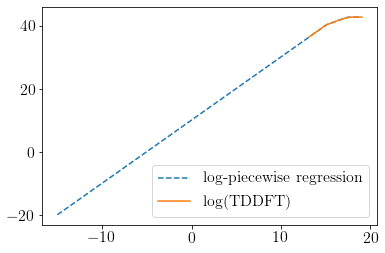

In [131]:
plt.figure()
plt.plot(Intensity_log, model.predict(Intensity_log), "--", label="log-piecewise regression")
plt.plot(np.log10(0.5*c*epsilon_0*data.Efield1**2), np.log10(data.Wpi), "-", label="log(TDDFT)")
plt.legend(loc="best")
plt.show()

Fitting logs of the TDDFT data is working very well. We can extend the interval of definition and export a sufficiently continuous function for the simulation code. 

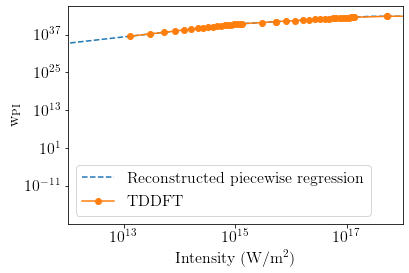

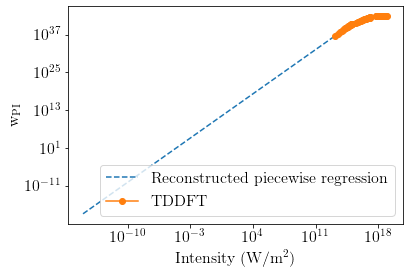

In [139]:
# Efield1 = np.power(10., Efield1_log)
# PeakIntensity = 0.5*c*epsilon_0*Efield1**2
PeakIntensity = np.power(10., Intensity_log)
Wpi_extrapolated = np.power(10.,model.predict(Intensity_log))
Wpi = model.predict(Intensity_log)

plt.figure()
plt.loglog(PeakIntensity, Wpi_extrapolated, "--", label="Reconstructed piecewise regression")
plt.loglog(0.5*c*epsilon_0*data.Efield1**2, data.Wpi, "-o", label="TDDFT")
plt.xlim([1E12,1E18])
# plt.xlabel("Field (V/m)")
plt.xlabel(r"Intensity (W/m$^{2}$)")
plt.ylabel("w$_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

plt.figure()
plt.loglog(PeakIntensity, Wpi_extrapolated, "--", label="Reconstructed piecewise regression")
plt.loglog(0.5*c*epsilon_0*data.Efield1**2, data.Wpi, "-o", label="TDDFT")
# plt.xlim([1E12,1E18])
# plt.xlabel("Field (V/m)")
plt.xlabel(r"Intensity (W/m$^{2}$)")
plt.ylabel("w$_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

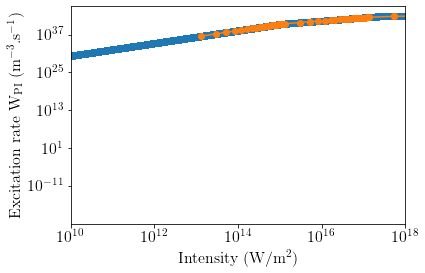

In [142]:
plt.figure()
plt.loglog(PeakIntensity, Wpi_extrapolated, "-o", label="Ready for export")
plt.loglog(0.5*c*epsilon_0*data.Efield1**2, data.Wpi, "-o", label="TDDFT")
plt.xlim([1E10,1E18])
plt.xlabel(r"Intensity (W/m$^{2}$)")
plt.ylabel(r"Excitation rate W$_{\mathrm{PI}}$ (m$^{-3}$.s$^{-1}$)")
plt.show()

### Extrapolation using adjusted multi-photon formulas

Other possible formulas for adjusting the rate are: 
* Gruzdev, V. Fundamental mechanisms of laser damage of dielectric crystals by ultrashort pulse: ionization dynamics for the Keldysh model Optical Engineering, 2014, 53, 122515-122515
* Shcheblanov, N. S.; Povarnitsyn, M. E.; Terekhin, P. N.; Guizard, S. & Couairon, A. Nonlinear photoionization of transparent solids: A nonperturbative theory obeying selection rules Physical Review A, 2017, 96, 063410
* Perelomov, A. M.; Popov, V. S. & Terent'ev, M. V. Ionization of atoms in an alternating electric field Sov. Phys. JETP., 1966, 23, 924-934

## Export to CSV file

### Export excitation rates

In [143]:
import spp_extended_theory.Libs.libDatabase as libDatabase
ArrayToExport=np.array([PeakIntensity, Wpi_extrapolated]).T
Egap=2.56*e #experimental value of direct band gap
libDatabase.ExportToTxt(ArrayToExport, "TDDFT-LDA.csv", header="Gap: "+str(round(Egap/e,1))+"eV\nWavelength: "+str(1E9*wavelength)+"nm"+"\nn x I\tWpiTDDFT")
# libDatabase.ExportToTxt(ArrayToExport, "TDDFT-TB09.csv", header="Gap: "+str(round(Egap/e,1))+"eV\nWavelength: "+str(1E9*wavelength)+"nm"+"\nn x I\tWpiTDDFT")

0

### Export number of photons

In [144]:
I_th2=list(np.power(10e0,I_th)) #expresses back to absolute values instead of log10
# Change first value to 0 (as first value is lower bound of TDDFT intensity)
I_th2[0]=0e0
# Add sone value at the end of the table, to render infinite intensity
I_th2.append(1e100)
print(I_th2)

[0.0, 1131308096111039.5, 2.4195054311625808e+17, 1.0750395848371431e+19, 1e+100]


In [145]:
# Duplicate first value
n_ph2=[]
n_ph2.append(n_ph[0])
for elem in n_ph:
    n_ph2.append(elem)
n_ph2

# Add duplicated value at the end for representing infinite intensity
n_ph2.append(n_ph2[len(n_ph2)-1])
n_ph2

[2.002924864740547,
 2.002924864740547,
 1.0303724787171256,
 0.03750878777012709,
 0.03750878777012709]

In [146]:
print(I_th2)
print(n_ph2)

[0.0, 1131308096111039.5, 2.4195054311625808e+17, 1.0750395848371431e+19, 1e+100]
[2.002924864740547, 2.002924864740547, 1.0303724787171256, 0.03750878777012709, 0.03750878777012709]


In [148]:
ArrayToExport=np.array([I_th2, n_ph2]).T
libDatabase.ExportToTxt(ArrayToExport, "TDDFT-LDA-nph.csv", header="# Number of photons as function of intensity. Dont remove duplicated values. \n#I_th\tn_ph")

0